# Okun's law: growth and unemployment

Examine the association between US real GDP growth and changes in unemployment.
Compare linear and quadratic OLS specifications, then use one rolling window
to examine changes in the simple-model slope.

The sample contains **183 quarters, 1980Q1–2025Q3**. GDP growth is a **simple
percentage change**, and the rolling window contains **40 quarters** (10 years).

Data Sources:

- BEA [real GDP, GDPC1](https://fred.stlouisfed.org/series/GDPC1), through FRED;
- BLS [unemployment rate, UNRATE](https://fred.stlouisfed.org/series/UNRATE), through FRED.

The application is inspired by [Ball, Leigh and Loungani (2017), *Okun's Law:
Fit at 50?*](https://doi.org/10.1111/jmcb.12420). It is a teaching adaptation
using a contemporaneous changes equation, rather than a replication of the paper.
Data are included locally; no download is needed.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

In [3]:
# GDP is quarterly and seasonally adjusted. UNRATE is the arithmetic mean
# of all three monthly, seasonally adjusted observations in each quarter.
# 1979Q4 supplies the base for first differences; it is not an estimation row.
levels = pd.read_csv(DATA_DIR / "quarterly_okun_data.csv", parse_dates=["date"]).set_index("date")
if levels.isna().any().any() or not levels["real_gdp"].gt(0).all():
    raise ValueError("Missing observations or non-positive GDP: inspect the CSV.")
if not levels["unemployment_months"].eq(3).all():
    raise ValueError("A quarterly unemployment rate needs all three monthly observations.")
quarters = levels.index.to_period("Q")
if not quarters.equals(pd.period_range(quarters[0],quarters[-1],freq="Q")):
    raise ValueError("Missing or duplicate quarters: do not treat gaps as adjacent observations.")
# October 2025 unemployment was not collected by BLS. Stop at 2025Q3;
# do not replace it or average only November and December for 2025Q4.
display(levels.head().round(3))

,real_gdp,unemployment_rate,unemployment_months
date,,,
1979-12-31,7318.535,5.967,3
1980-03-31,7341.557,6.300,3
1980-06-30,7190.289,7.333,3
1980-09-30,7181.743,7.667,3
1980-12-31,7315.677,7.400,3


## Growth and unemployment changes

Calculate quarterly real GDP growth and the change in the unemployment rate:

$$g_t=100\left(\frac{Y_t}{Y_{t-1}}-1\right),\qquad
\Delta U_t=U_t-U_{t-1}.$$

Growth is the percentage change **from one quarter to the next**, without
annualisation. The annual-rate scaling of GDP cancels in the ratio.
Unemployment changes are in **percentage points**: a move from 5% to 6% is
+1 point. The model relates these changes, rather than the two levels.

In [4]:
data = levels.copy()
data["growth"] = 100 * data["real_gdp"].pct_change(fill_method=None)
data["change_u"] = data["unemployment_rate"].diff()
data["growth_sq"] = data["growth"]**2
data = data.iloc[1:].copy()  # Remove only the supplied base quarter.
if data.isna().any().any():
    raise ValueError("Missing estimation observations: inspect the data.")
print(f"Estimation sample: {len(data)} quarters, {data.index[0].to_period('Q')}–{data.index[-1].to_period('Q')}")
display(data[["growth", "change_u"]].head().round(3))

Estimation sample: 183 quarters, 1980Q1–2025Q3


,growth,change_u
date,,
1980-03-31,0.315,0.333
1980-06-30,-2.060,1.033
1980-09-30,-0.119,0.333
1980-12-31,1.865,-0.267
1981-03-31,1.959,0.033


## Linear and quadratic OLS

The simple changes version of Okun's relationship is

$$\Delta U_t=\alpha+\beta g_t+u_t.$$

A negative $\beta$ associates stronger growth with a smaller increase or
a larger decline in unemployment. It measures unemployment percentage points
per one-percentage-point increase in GDP growth. Alpha is the fitted unemployment
change at zero growth.

Allow curvature by including growth and its square together:

$$\Delta U_t=\alpha+\beta g_t+\gamma g_t^2+u_t.$$

OLS still applies because the model is linear in its coefficients. In the
quadratic model, $\beta$ is the slope **at zero growth**, and $\gamma$ describes
curvature. It is not correct to interpret $\beta$ as a constant slope at every
growth rate.

Use one HAC specification throughout: **four quarterly lags**, Bartlett weights,
sample-size correction and approximate $t$ inference. These are contemporaneous
associations; HAC allows heteroskedasticity and serial correlation in inference,
but does not establish causality or correct an unsuitable mean model.

In [5]:
HAC_LAGS = 4

def fit_ols(sample, quadratic=False):
    columns = ["growth", "growth_sq"] if quadratic else ["growth"]
    X = sm.add_constant(sample[columns], has_constant="add")
    ols = sm.OLS(sample["change_u"], X, missing="raise").fit()
    hac = ols.get_robustcov_results(cov_type="HAC", maxlags=HAC_LAGS,
                                  use_correction=True, use_t=True)
    return ols, hac

full_ols, full_hac = fit_ols(data)
quad_ols, quad_hac = fit_ols(data, quadratic=True)
rows = []
for name, ols, hac in [("Linear", full_ols, full_hac), ("Quadratic", quad_ols, quad_hac)]:
    interval = hac.conf_int(alpha=0.05)
    for j, term in enumerate(ols.model.exog_names):
        rows.append({"Model": name, "Term": term, "Estimate": hac.params[j],
                     "HAC SE": hac.bse[j], "p-value (H0: coefficient = 0)": hac.pvalues[j],
                     "95% lower": interval[j, 0], "95% upper": interval[j, 1]})
coefficients = pd.DataFrame(rows).set_index(["Model", "Term"])
fit_comparison = pd.DataFrame({"Linear": {"n": int(full_ols.nobs), "R-squared": full_ols.rsquared,
                                                        "Adjusted R-squared": full_ols.rsquared_adj},
                               "Quadratic": {"n": int(quad_ols.nobs), "R-squared": quad_ols.rsquared,
                                                              "Adjusted R-squared": quad_ols.rsquared_adj}}).T
with pd.option_context("display.float_format", "{:.4g}".format):
    display(coefficients)
    display(fit_comparison)

Estimate   HAC SE  p-value (H0: coefficient = 0)  \
Model     Term                                                          
Linear    const        0.4118   0.1105                      0.0002594   
          growth       -0.638   0.1415                      1.171e-05   
Quadratic const        0.3479  0.07956                      2.067e-05   
          growth      -0.6296   0.1224                      6.974e-07   
          growth_sq   0.03689 0.009332                      0.0001107   

                     95% lower  95% upper  
Model     Term                             
Linear    const         0.1937     0.6298  
          growth       -0.9172    -0.3587  
Quadratic const         0.1909     0.5049  
          growth       -0.8711    -0.3881  
          growth_sq    0.01848    0.05531

,n,R-squared,Adjusted R-squared
Linear,183,0.6903,0.6886
Quadratic,183,0.7713,0.7688


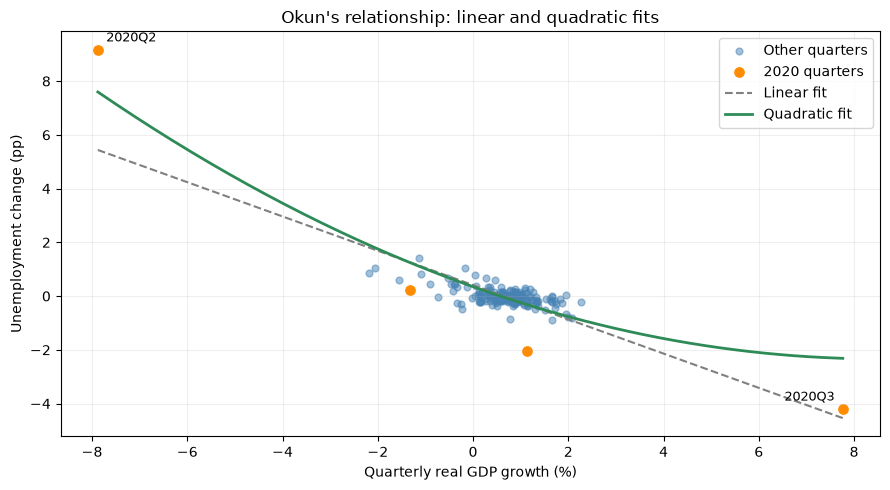

In [6]:
grid = np.linspace(data["growth"].min(), data["growth"].max(), 200)
X_grid = pd.DataFrame({"const": 1., "growth": grid, "growth_sq": grid**2})
in_2020 = data.index.year == 2020
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(data.loc[~in_2020, "growth"], data.loc[~in_2020, "change_u"],
           color="steelblue", alpha=0.5, s=24, label="Other quarters")
ax.scatter(data.loc[in_2020, "growth"], data.loc[in_2020, "change_u"],
           color="darkorange", s=45, label="2020 quarters")
ax.plot(grid, full_ols.predict(X_grid[["const", "growth"]]), color="grey",
        linestyle="--", label="Linear fit")
ax.plot(grid, quad_ols.predict(X_grid), color="seagreen", linewidth=2,
        label="Quadratic fit")
for quarter in ["2020Q2", "2020Q3"]:
    row = data.loc[data.index.to_period("Q") == quarter].iloc[0]
    right = row["growth"] > 0
    ax.annotate(quarter, (row["growth"], row["change_u"]),
                xytext=(-6 if right else 6, 6), textcoords="offset points",
                ha="right" if right else "left", fontsize=9)
ax.set(xlabel="Quarterly real GDP growth (%)", ylabel="Unemployment change (pp)",
       title="Okun's relationship: linear and quadratic fits")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

## Interpreting the quadratic term

The local slope at growth $g$ is $\beta+2\gamma g$. For a full one-point
increase from $g$ to $g+1$, the fitted change is $\beta+\gamma(2g+1)$.
The derivative and the finite change need not be equal.

Compare the implied slopes at growth rates of -1%, 0% and 1%. A curved fitted
line can describe different responses in contractions and expansions, but
extreme quarters can strongly affect its shape. All observations, including
2020, remain in the regressions.

In [7]:
growth_points = np.array([-1., 0., 1.])
alpha, beta, gamma = quad_hac.params
interpretation = pd.DataFrame({
    "Growth (%)": growth_points,
    "Fitted unemployment change (pp)": alpha + beta * growth_points + gamma * growth_points**2,
    "Local slope (pp per growth point)": beta + 2 * gamma * growth_points,
    "Fitted change for +1 growth point (pp)": beta + gamma * (2 * growth_points + 1)
}).set_index("Growth (%)")
display(interpretation.round(4))

,Fitted unemployment change (pp),Local slope (pp per growth point),Fitted change for +1 growth point (pp)
Growth (%),,,
-1.0,1.0144,-0.7034,-0.6665
0.0,0.3479,-0.6296,-0.5927
1.0,-0.2447,-0.5558,-0.5189


## Rolling the simple model

Use **40-quarter windows** for the linear model only. Each window has its own
intercept and slope, and is dated at its final quarter. This gives 144 complete
windows, from the window ending in 1989Q4 through that ending in 2025Q3.

The slope summarises the relationship within a ten-year window, rather than
the final quarter alone. The shaded bands are pointwise 95% HAC intervals.
Adjacent windows share 39 observations, so estimates are not independent.

Rolling estimates: 144 | Quarters per window: 40


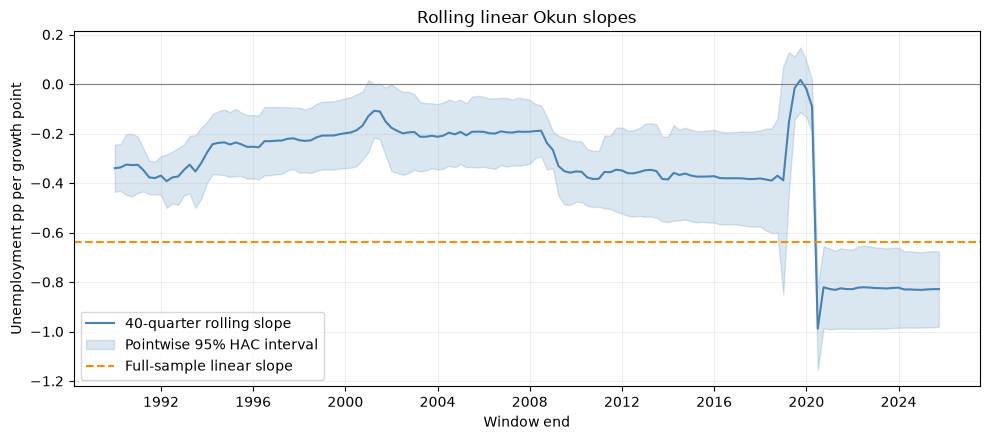

In [8]:
WINDOW = 40
records = []
for end in range(WINDOW, len(data) + 1):
    sample = data.iloc[end - WINDOW:end]
    ols, hac = fit_ols(sample)
    ci = hac.conf_int(alpha=0.05)
    records.append({"end": sample.index[-1], "start": sample.index[0], "n": int(ols.nobs),
                    "beta": hac.params[1], "SE": hac.bse[1],
                    "lower": ci[1, 0], "upper": ci[1, 1]})
rolling = pd.DataFrame(records).set_index("end")
print(f"Rolling estimates: {len(rolling)} | Quarters per window: {WINDOW}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rolling.index, rolling["beta"], color="steelblue", label="40-quarter rolling slope")
ax.fill_between(rolling.index, rolling["lower"].to_numpy(), rolling["upper"].to_numpy(),
                color="steelblue", alpha=0.2, label="Pointwise 95% HAC interval")
ax.axhline(full_hac.params[1], color="darkorange", linestyle="--", label="Full-sample linear slope")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(xlabel="Window end", ylabel="Unemployment pp per growth point",
       title="Rolling linear Okun slopes")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

Changing linear slopes can reflect parameter changes, sampling uncertainty,
influential observations or a curved relationship combined with a changing
distribution of growth. The plots help describe these possibilities; they
are not a formal test of a structural break. A longer window would average
over more history, while a shorter window would generally respond faster
and be noisier.